# F8 · Detector training: process and results, 2026-10-28

Visual analysis of the two 50-epoch DINO-DETR runs in `spec/2026-10-26-detector-training-pipeline/` (`results.md`), launched with

```bash
for E in det_rgb det_ir; do IRWM_STAGE_DATA=1 bash slurm/submit.sh ctcomp3 projects/detection/train.py experiment=$E \
    cluster.timeout_min=1200 cluster.cpus_per_task=8 cluster.num_workers=8 cluster.mem_gb=32; done
```

The two heads are the **frozen decoders** of everything that follows: F9 scores them on real video-test features (H1),
F12 on DINO-Foresight's predicted features (H2). This notebook checks that they trained cleanly and shows how they got
where they are, so later gaps can be attributed to the features and not to an under- or over-trained head.

**Headline:**
- **Both detectors learn and stay healthy.** Training loss falls to ≈ 0.22× its first epoch, fp16 never produced a non-finite step, and both 256-frame overfits passed.
- **Best `val/AP`: RGB 0.302 (epoch 14), thermal 0.330 (epoch 34).** AP50 for person and car is 0.64–0.81, well above the 0.30 done bar.
- **RGB overfits after epoch 14; thermal plateaus.** RGB loses 0.027 AP by epoch 49 while its training loss keeps falling. Thermal stays within 0.01 of its best from epoch 14 to 44. Best-`val/AP` selection protects both exports.
- **The head, not the encoder, sets the cost:** the encoder is 12 % of a 1.52 s step; ≈ 14 GPU-hours per detector on an L4.
- **The RGB/thermal AP gap here is not H1.** The val sets differ, there is one seed, and val was also used for selection (§9).

The notebook only **reads** the run dirs, the offline W&B logs and the frozen exports listed below.
Setup: `uv sync --group notebook`.

In [1]:
import hashlib
import json
import re
import struct
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from omegaconf import OmegaConf
from wandb.proto import wandb_internal_pb2 as pb

from irwm.data.classes import CLASS_NAMES

# Run dirs and checkpoints copied from the cluster into <repo>/; falls back to $IRWM_OUTPUT_ROOT / $IRWM_CKPT_ROOT.
OUT, CKPT = Path("../outputs"), Path("../checkpoints")
if not (OUT.is_dir() and CKPT.is_dir()):
    from irwm.utils.paths import ckpt_root, load_env, output_root

    load_env()
    OUT, CKPT = output_root(), ckpt_root()

# key: (run dir, modality, kind)
RUNS = {
    "det_rgb": ("detection/2026-10-27/12-27-09", "rgb", "full"),
    "det_ir": ("detection/2026-10-27/12-28-00", "thermal", "full"),
    "overfit_rgb": ("detection/2026-10-27/11-12-19", "rgb", "overfit"),
    "overfit_ir": ("detection/2026-10-27/11-12-33", "thermal", "overfit"),
}
FULL = ["det_rgb", "det_ir"]
OVERFIT = ["overfit_rgb", "overfit_ir"]
LR_DROP_EPOCH = 40  # MultiStepLR milestone (E5), 0-based: epochs 40-49 run at 0.1x lr
DONE_BAR = 0.30  # AP50 for person and car (Roadmap F8)


def wandb_log(run_dir):
    """(path, history rows, system-metric rows) of a run's offline `.wandb` log.

    The file is a LevelDB-style log: a 7-byte header, then 32 KiB blocks of chunks, each with a
    7-byte crc/length/type header (1 = full record, 2/3/4 = first/middle/last fragment). Every
    record is a `wandb.proto.Record`. wandb 0.30 no longer ships a Python reader for it.
    """
    (path,) = (OUT / run_dir / "wandb").glob("run-*/run-*.wandb")
    data = path.read_bytes()
    assert data[:4] == b":W&B", path
    history, stats, pos, buf = [], [], 7, b""
    while pos + 7 <= len(data):
        left = 32768 - pos % 32768
        if left < 7:  # block trailer too short for a chunk header
            pos += left
            continue
        _, n, kind = struct.unpack("<IHB", data[pos:pos + 7])
        pos += 7
        if kind == 0:  # zero padding to the end of the block
            pos += left - 7
            continue
        buf += data[pos:pos + n]
        pos += n
        if kind not in (1, 4):
            continue
        rec = pb.Record()
        rec.ParseFromString(buf)
        buf = b""
        if rec.HasField("history"):
            history.append({i.key or "/".join(i.nested_key): json.loads(i.value_json) for i in rec.history.item})
        elif rec.HasField("stats"):
            row = {i.key: json.loads(i.value_json) for i in rec.stats.item}
            row["_timestamp"] = rec.stats.timestamp.seconds + rec.stats.timestamp.nanos / 1e9
            stats.append(row)
    return path, history, stats


def read_json(path):
    return json.loads(Path(path).read_text())


WB = {k: wandb_log(d) for k, (d, *_) in RUNS.items()}
WB_META = {k: read_json(next((OUT / d / "wandb").glob("run-*/files/wandb-metadata.json"))) for k, (d, *_) in RUNS.items()}
CFG = {k: OmegaConf.load(OUT / d / ".hydra/config.yaml") for k, (d, *_) in RUNS.items()}
VAL = {k: {int(p.stem[-3:]): read_json(p) for p in sorted((OUT / RUNS[k][0] / "val_metrics").glob("epoch_*.json"))}
       for k in FULL}
SUMMARY = {k: read_json(OUT / RUNS[k][0] / "train_summary.json") for k in FULL}
OVERFIT_JSON = {k: read_json(OUT / RUNS[k][0] / "overfit.json") for k in OVERFIT}
FROZEN = {k: read_json(CKPT / "detection/frozen" / k / "meta.json") for k in FULL}
assert all(CFG[k].modality == RUNS[k][1] for k in RUNS)


def series(k, key, x="trainer/global_step"):
    """(x, y) arrays of every W&B history row of run k that logged `key`."""
    rows = [r for r in WB[k][1] if key in r]
    return np.array([r[x] for r in rows], float), np.array([r[key] for r in rows], float)


def per_epoch(k, key):
    """Epoch-level series (logged once per epoch), indexed by 0-based epoch."""
    ep, y = series(k, key, x="epoch")
    assert np.array_equal(ep, np.arange(len(ep))), f"{k}: {key} not logged once per epoch"
    return y


def steps_per_epoch(k):
    return round((series(k, "train/loss_epoch")[0][-1] + 1) / len(per_epoch(k, "train/loss_epoch")))


def val_epochs(k):
    return np.array(sorted(VAL[k]))


def val_metric(k, key):
    return np.array([VAL[k][e]["metrics"][key] for e in val_epochs(k)])


for k in RUNS:
    path, hist, stats = WB[k]
    print(f"{k:12s} {RUNS[k][0]}  W&B {path.stem[4:]}  {len(hist)} history rows, {len(stats)} system rows")

det_rgb      detection/2026-10-27/12-27-09  W&B 6xlqcqo3  688 history rows, 6450 system rows
det_ir       detection/2026-10-27/12-28-00  W&B cdkr1ggq  714 history rows, 6690 system rows
overfit_rgb  detection/2026-10-27/11-12-19  W&B m1r6x9tv  44 history rows, 106 system rows
overfit_ir   detection/2026-10-27/11-12-33  W&B icp41qdw  86 history rows, 122 system rows


In [2]:
# Plot style, same as flir_stats.ipynb: modality in fixed categorical slots 1-2 (RGB blue, thermal orange).
# Every comparison in this notebook is RGB vs thermal, so modality is the only colour; classes, loss terms and
# metrics are small multiples instead of extra hues.
MOD_COLOR = {"rgb": "#2a78d6", "thermal": "#eb6834"}
MOD_LABEL = {"rgb": "RGB", "thermal": "Thermal"}
RUN_MOD = {k: m for k, (_, m, _) in RUNS.items()}
INK, MUTED, GRID, REF = "#0b0b0b", "#52514e", "#e6e5e0", "#a8a7a2"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def color(k):
    return MOD_COLOR[RUN_MOD[k]]


def label(k):
    return f"{MOD_LABEL[RUN_MOD[k]]} ({k})"


def table(header, rows):
    fmt = lambda v: f"{v:.4f}" if isinstance(v, float) else ("–" if v is None else str(v))
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(fmt(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def mark_lr_drop(ax, text=True):
    ax.axvline(LR_DROP_EPOCH - 0.5, color=REF, lw=1, ls="--", zorder=0)
    if text:
        ax.text(LR_DROP_EPOCH - 0.2, 1, "lr ×0.1", transform=ax.get_xaxis_transform(),
                ha="left", va="top", fontsize=7.5, color=MUTED)


def mark_best(ax, k, key="AP"):
    best = SUMMARY[k]["best_epoch"]
    y = VAL[k][best]["metrics"][key]
    ax.plot(best, y, marker="*", ms=12, color=color(k), mec="white", mew=1.2, zorder=5)
    return best, y

## 1. Runs and provenance

One row per SLURM job. GPU and host come from the W&B metadata, the job id from the staged `data_root`, the commit from
each run's own `train_summary.json` / `overfit.json`. The full runs must be at `b81ef6c` and clean.

In [3]:
def job_id(d):
    return re.search(r"/(\d{7})/", d["data_root"]).group(1)


rows = []
for k in RUNS:
    d = SUMMARY.get(k) or OVERFIT_JSON[k]
    meta = WB_META[k]
    epochs = int(max(r.get("epoch", -1) for r in WB[k][1])) + 1
    rows.append([k, MOD_LABEL[RUN_MOD[k]], job_id(d), meta["host"], meta["gpu"], f"`{WB[k][0].stem[4:]}`",
                 f"`{d['git']['commit'][:7]}`", d["git"]["dirty"], f"{d['n_train_frames']:,} (+{d['n_dropped_empty']})",
                 f"{d['n_val_frames']:,}", epochs, f"{int(series(k, 'trainer/global_step')[1].max()) + 1:,}",
                 f"{d['fit_wall_s'] / 3600:.2f}"])
table(["run", "modality", "SLURM job", "host", "GPU", "W&B", "commit", "dirty", "train frames (+empty dropped)",
       "val frames", "epochs", "steps", "fit wall (h)"], rows)

for k in FULL:
    assert SUMMARY[k]["git"] == {"commit": "b81ef6cc191dac864828dd1e991950bce13fb3a9", "dirty": False}
    assert all(v["git"] == SUMMARY[k]["git"] for v in VAL[k].values())
    assert len(VAL[k]) == 10 and list(val_epochs(k)) == list(range(4, 50, 5))
print("full runs: commit b81ef6c, clean, 10 validations at epochs 4, 9, ..., 49 (0-based)")
print("steps per epoch:", {k: steps_per_epoch(k) for k in FULL}, "(batch 16, last partial batch dropped)")

| run | modality | SLURM job | host | GPU | W&B | commit | dirty | train frames (+empty dropped) | val frames | epochs | steps | fit wall (h) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| det_rgb | RGB | 5526115 | hpc-gpu5 | NVIDIA L4 | `6xlqcqo3` | `b81ef6c` | False | 10,038 (+280) | 1,085 | 50 | 31,350 | 13.43 |
| det_ir | Thermal | 5526116 | hpc-gpu6 | NVIDIA L4 | `cdkr1ggq` | `b81ef6c` | False | 10,462 (+280) | 1,144 | 50 | 32,650 | 13.94 |
| overfit_rgb | RGB | 5526084 | hpc-gpu5 | NVIDIA L4 | `m1r6x9tv` | `6425d4c` | False | 256 (+0) | 256 | 32 | 500 | 0.22 |
| overfit_ir | Thermal | 5526085 | hpc-gpu1 | Tesla V100S-PCIE-32GB | `icp41qdw` | `6425d4c` | False | 256 (+0) | 256 | 63 | 1,000 | 0.25 |

full runs: commit b81ef6c, clean, 10 validations at epochs 4, 9, ..., 49 (0-based)
steps per epoch: {'det_rgb': 627, 'det_ir': 653} (batch 16, last partial batch dropped)


- Both full runs ran on an **NVIDIA L4** (project's worst-case GPU), with no requeue, and completed all 50 epochs.
- The thermal train split is 4 % larger (10,462 vs 10,038 frames), so thermal has 653 vs 627 steps per epoch.
  Both drop 280 frames with no kept box.
- The overfits ran a commit earlier (`6425d4c`); the only change to `b81ef6c` is per-epoch logging (plan.md amendment 2026-10-27).
  The thermal overfit landed on a **V100S**, so its timing is not comparable with the others.

## 2. Training loss

`train/loss` is logged every 50 steps (light line) and as an epoch mean (`train/loss_epoch`, solid). It is the full DINO
objective: the final decoder layer, the 5 auxiliary decoder layers and the two-stage encoder proposals, each with focal
class, L1 box and GIoU terms, for both the matching and the denoising queries. Log scale.

| run | epoch 0 | epoch 14 | epoch 39 | epoch 40 | epoch 49 | 49 / 0 (bar ≤ 0.5) | 40 / 39 (lr drop) |
|---|---|---|---|---|---|---|---|
| det_rgb | 19.4392 | 9.2947 | 6.2146 | 5.5618 | 4.5574 | 0.2344 | 0.8950 |
| det_ir | 19.0410 | 8.4031 | 5.6657 | 5.0410 | 4.1305 | 0.2169 | 0.8897 |

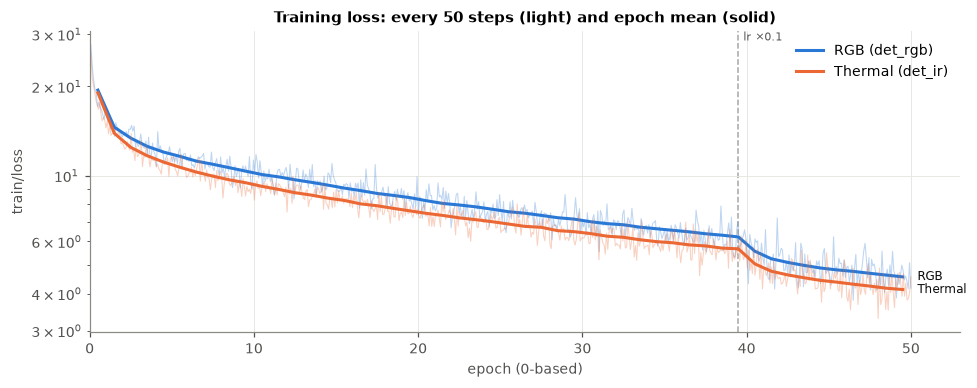

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for k in FULL:
    step, loss = series(k, "train/loss_step")
    ax.plot(step / steps_per_epoch(k), loss, color=color(k), lw=0.7, alpha=0.3)
    ep_loss = per_epoch(k, "train/loss_epoch")
    ax.plot(np.arange(len(ep_loss)) + 0.5, ep_loss, color=color(k), lw=2, label=label(k))
    ax.text(50.4, ep_loss[-1], MOD_LABEL[RUN_MOD[k]], color=INK, fontsize=8, va="center")
mark_lr_drop(ax)
ax.set_yscale("log")
ax.set_xlim(0, 53)
ax.set_xlabel("epoch (0-based)")
ax.set_ylabel("train/loss")
ax.set_title("Training loss: every 50 steps (light) and epoch mean (solid)")
ax.legend(loc="upper right")
fig.tight_layout()

rows = []
for k in FULL:
    l = per_epoch(k, "train/loss_epoch")
    rows.append([k, l[0], l[14], l[39], l[40], l[49], l[49] / l[0], l[40] / l[39]])
table(["run", "epoch 0", "epoch 14", "epoch 39", "epoch 40", "epoch 49", "49 / 0 (bar ≤ 0.5)", "40 / 39 (lr drop)"], rows)

- **Both runs learn**: the epoch loss falls to 0.23× (RGB) and 0.22× (thermal) of epoch 0, well inside the ≤ 0.5 bar.
- **The lr drop at epoch 40 gives a visible step down**, then the loss flattens: the 1e-5 phase mostly polishes the fit.
- The two curves are almost parallel. Thermal sits slightly lower throughout, but the loss is not comparable across
  modalities (different images, different boxes), so this says nothing about H1.

### 2.1 Loss terms

The six terms the detector reports for the **final decoder layer**: focal class, L1 box and GIoU, for the matching
(one-to-one, top row) and the denoising queries (bottom row). Each point is the mean of that epoch's 50-step samples.
These terms are what the inference output depends on; the auxiliary-layer terms follow the same shape.

| run | queries | class 49/0 | L1 49/0 | GIoU 49/0 |
|---|---|---|---|---|
| det_rgb | matching | 0.04 | 0.17 | 0.28 |
| det_rgb | denoising | 0.05 | 0.17 | 0.26 |
| det_ir | matching | 0.03 | 0.19 | 0.29 |
| det_ir | denoising | 0.05 | 0.18 | 0.25 |

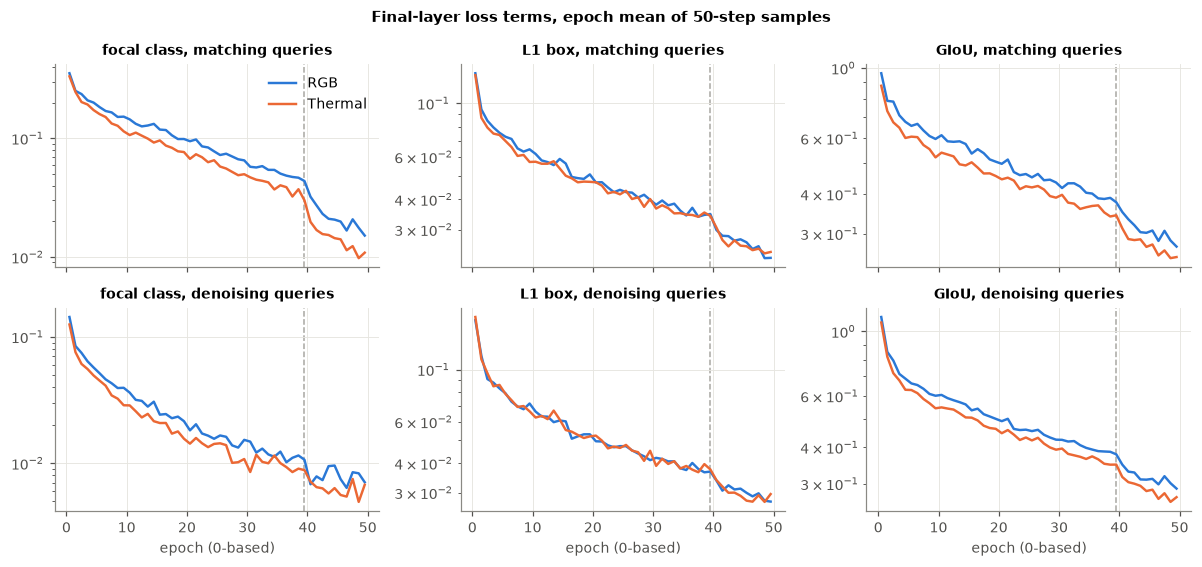

In [5]:
TERMS = [("class", "focal class"), ("bbox", "L1 box"), ("giou", "GIoU")]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), sharex=True)
for row, (suffix, title) in enumerate([("", "matching queries"), ("_dn", "denoising queries")]):
    for col, (term, name) in enumerate(TERMS):
        ax = axes[row, col]
        for k in FULL:
            step, y = series(k, f"train/loss_{term}{suffix}")
            ep = (step // steps_per_epoch(k)).astype(int)
            means = np.array([y[ep == e].mean() for e in range(50)])
            ax.plot(np.arange(50) + 0.5, means, color=color(k), lw=1.6, label=MOD_LABEL[RUN_MOD[k]])
        mark_lr_drop(ax, text=False)
        ax.set_yscale("log")
        ax.set_title(f"{name}, {title}", fontsize=9)
        if row == 1:
            ax.set_xlabel("epoch (0-based)")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Final-layer loss terms, epoch mean of 50-step samples", fontweight="bold", fontsize=10)
fig.tight_layout()

rows = []
for k in FULL:
    for suffix in ["", "_dn"]:
        r = [k, "denoising" if suffix else "matching"]
        for term, _ in TERMS:
            step, y = series(k, f"train/loss_{term}{suffix}")
            ep = step // steps_per_epoch(k)
            r.append(f"{y[ep == 49].mean() / y[ep == 0].mean():.2f}")
        rows.append(r)
table(["run", "queries", "class 49/0", "L1 49/0", "GIoU 49/0"], rows)

- Every term falls in both runs; none stalls or diverges. The **class term drops the most**, the box terms less:
  late training mostly sharpens the scores, which is where RGB's val AP starts to suffer (§3).
- The denoising class term is lower than the matching one (each noised query already knows its target); the box terms
  of the two query sets are about the same. All fall in step.
- Thermal's class and GIoU terms sit below RGB's throughout, while the L1 box terms overlap. Again a training
  diagnostic, not a modality comparison.

## 3. Validation curves

COCO AP on the full val split (`val_metrics/epoch_<NNN>.json`, pycocotools, ignore regions as crowd GT), every 5 epochs.
The star marks the checkpoint kept by best-`val/AP` selection (E6), which is the one exported.

| run | best epoch | best AP | AP at epoch 49 | last − best | range from epoch 14 on |
|---|---|---|---|---|---|
| det_rgb | 14 | 0.3021 | 0.2747 | -0.0274 | 0.0274 |
| det_ir | 34 | 0.3297 | 0.3162 | -0.0134 | 0.0134 |

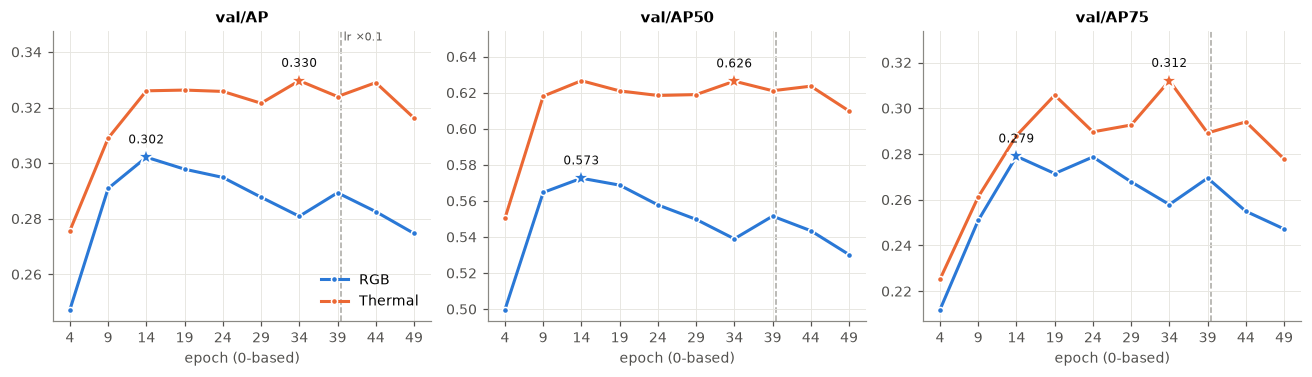

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True)
for ax, key in zip(axes, ["AP", "AP50", "AP75"]):
    for k in FULL:
        ax.plot(val_epochs(k), val_metric(k, key), color=color(k), lw=2, marker="o", ms=4,
                mec="white", mew=1, label=MOD_LABEL[RUN_MOD[k]])
        best, y = mark_best(ax, k, key)
        ax.annotate(f"{y:.3f}", (best, y), xytext=(0, 9), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
    mark_lr_drop(ax, text=key == "AP")
    ax.set_title(f"val/{key}")
    ax.set_xlabel("epoch (0-based)")
    ax.set_xticks(val_epochs("det_rgb"))
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.15 * (hi - lo))
axes[0].legend(loc="lower right")
fig.tight_layout()

rows = []
for k in FULL:
    ap = val_metric(k, "AP")
    best = SUMMARY[k]["best_epoch"]
    rows.append([k, best, ap.max(), ap[-1], ap[-1] - ap.max(), ap[val_epochs(k) >= 14].max() - ap[val_epochs(k) >= 14].min()])
table(["run", "best epoch", "best AP", "AP at epoch 49", "last − best", "range from epoch 14 on"], rows)

- **RGB peaks early.** AP is highest at epoch 14 (0.302) and drifts down to 0.275 by epoch 49. The small rise at
  epoch 39 comes *before* the lr drop (validation 39 runs at the end of epoch 39, still at 1e-4), so it is noise
  rather than an lr effect. After the drop, the decline continues (0.283, 0.275).
- **Thermal plateaus.** It moves within 0.014 AP from epoch 14 to 49, and its best (epoch 34) is only 0.003 above epoch 19.
  The choice of epoch matters little for thermal.
- AP50 and AP75 follow AP for both runs, so the RGB decline is not only a localisation effect.

### 3.1 Training loss vs val AP

Each point is one validation: x is that epoch's training loss, y its val AP. Moving right means more training.
A detector that keeps generalising climbs to the right; one that overfits turns down while the loss keeps falling.

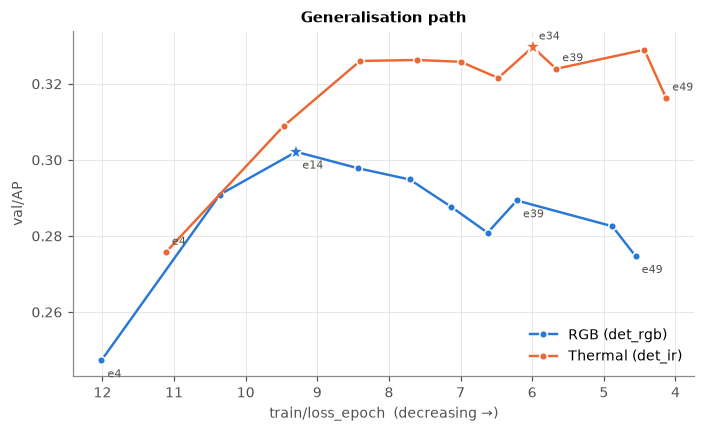

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for k in FULL:
    x = per_epoch(k, "train/loss_epoch")[val_epochs(k)]
    y = val_metric(k, "AP")
    ax.plot(x, y, color=color(k), lw=1.6, marker="o", ms=5, mec="white", mew=1, label=label(k))
    for e, xi, yi in zip(val_epochs(k), x, y):
        if e in (4, SUMMARY[k]["best_epoch"], 39, 49):
            ax.annotate(f"e{e}", (xi, yi), xytext=(4, 5 if k == "det_ir" else -11), textcoords="offset points",
                        fontsize=7.5, color=MUTED)
    best = SUMMARY[k]["best_epoch"]
    ax.plot(per_epoch(k, "train/loss_epoch")[best], VAL[k][best]["metrics"]["AP"], marker="*", ms=12,
            color=color(k), mec="white", mew=1.2, zorder=5)
ax.invert_xaxis()
ax.set_xlabel("train/loss_epoch  (decreasing →)")
ax.set_ylabel("val/AP")
ax.set_title("Generalisation path")
ax.legend(loc="lower right")
fig.tight_layout()

- **RGB turns over at e14** (star) while the training loss keeps falling from 9.3 to 4.6: the head fits the 10k RGB train
  frames better without getting better on val, which is the classic overfitting signature.
- **Thermal flattens** instead of turning over: more training neither helps nor hurts it much after e14.
- A plausible reason is that thermal frames carry less nuisance appearance (colour, lighting, glare) per object, so the
  head has less to memorise. That is a hypothesis; this run does not test it.

### 3.2 Per class

AP (top) and AP50 (bottom) per class over epochs. The dashed line in the person and car AP50 panels is the 0.30 done bar.
Classes are ordered as in `irwm.data.classes` (by frequency, F2).

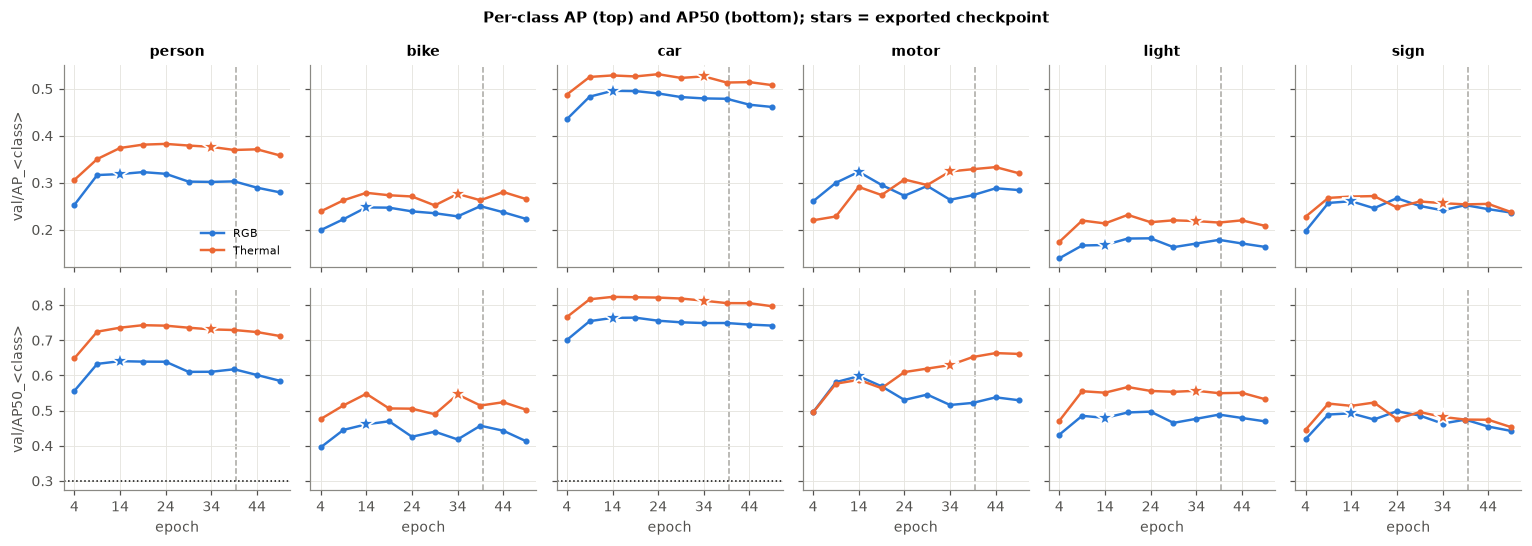

In [8]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5), sharex=True, sharey="row")
for row, key in enumerate(["AP", "AP50"]):
    for col, c in enumerate(CLASS_NAMES):
        ax = axes[row, col]
        for k in FULL:
            ax.plot(val_epochs(k), val_metric(k, f"{key}_{c}"), color=color(k), lw=1.6, marker="o", ms=3,
                    label=MOD_LABEL[RUN_MOD[k]])
            mark_best(ax, k, f"{key}_{c}")
        mark_lr_drop(ax, text=False)
        if key == "AP50" and c in ("person", "car"):
            ax.axhline(DONE_BAR, color=INK, lw=1, ls=":")
        ax.set_title(f"{c}" if row == 0 else "", fontsize=9)
        if col == 0:
            ax.set_ylabel(f"val/{key}_<class>")
        if row == 1:
            ax.set_xlabel("epoch")
            ax.set_xticks([4, 14, 24, 34, 44])
axes[0, 0].legend(loc="lower right", fontsize=7.5)
fig.suptitle("Per-class AP (top) and AP50 (bottom); stars = exported checkpoint", fontweight="bold", fontsize=10)
fig.tight_layout()

In [9]:
rows = []
for c in CLASS_NAMES:
    r = [c]
    for k in FULL:
        best, last = VAL[k][SUMMARY[k]["best_epoch"]]["metrics"], VAL[k][49]["metrics"]
        r += [f"{best[f'AP_{c}']:.3f} / {best[f'AP50_{c}']:.3f}", f"{last[f'AP_{c}'] - best[f'AP_{c}']:+.3f}"]
    rows.append(r)
table(["class", "det_rgb AP / AP50 (best)", "det_rgb ΔAP 49 − best", "det_ir AP / AP50 (best)", "det_ir ΔAP 49 − best"], rows)

| class | det_rgb AP / AP50 (best) | det_rgb ΔAP 49 − best | det_ir AP / AP50 (best) | det_ir ΔAP 49 − best |
|---|---|---|---|---|
| person | 0.318 / 0.641 | -0.039 | 0.376 / 0.731 | -0.018 |
| bike | 0.247 / 0.461 | -0.024 | 0.276 / 0.546 | -0.011 |
| car | 0.496 / 0.764 | -0.034 | 0.526 / 0.813 | -0.019 |
| motor | 0.323 / 0.598 | -0.039 | 0.324 / 0.630 | -0.004 |
| light | 0.167 / 0.479 | -0.004 | 0.218 / 0.557 | -0.010 |
| sign | 0.261 / 0.492 | -0.024 | 0.257 / 0.482 | -0.019 |

- **Car is the easiest class** in both modalities (AP ≈ 0.50–0.53), **light the hardest** (0.17–0.22): lights are small
  and numerous. Done bar: the lowest of the four person/car AP50 values is 0.641 (RGB person).
- **RGB's late decline is broad.** Every class but light loses 0.02–0.04 AP from epoch 14 to 49, most of all
  person and motor.
- **Thermal's per-class curves are flat** after epoch 14 (all within 0.02 AP of the export at epoch 49). The exception
  is thermal motor AP50, which keeps rising to ≈ 0.66 at epoch 44: the rare classes are still learning when the
  frequent ones have plateaued.
- Per-class cross-modality comparisons need the annotation asymmetry of Roadmap R10 and the F6 evaluator.
  They are shown here only as training diagnostics.

### 3.3 Object size

APS/M/L with areas normalised to a 640×512 frame (F2), so the buckets hold the same physical objects in both modalities.

| run | APs | APm | APl |
|---|---|---|---|
| det_rgb | 0.2764 | 0.4479 | 0.4679 |
| det_ir | 0.2519 | 0.5165 | 0.6478 |

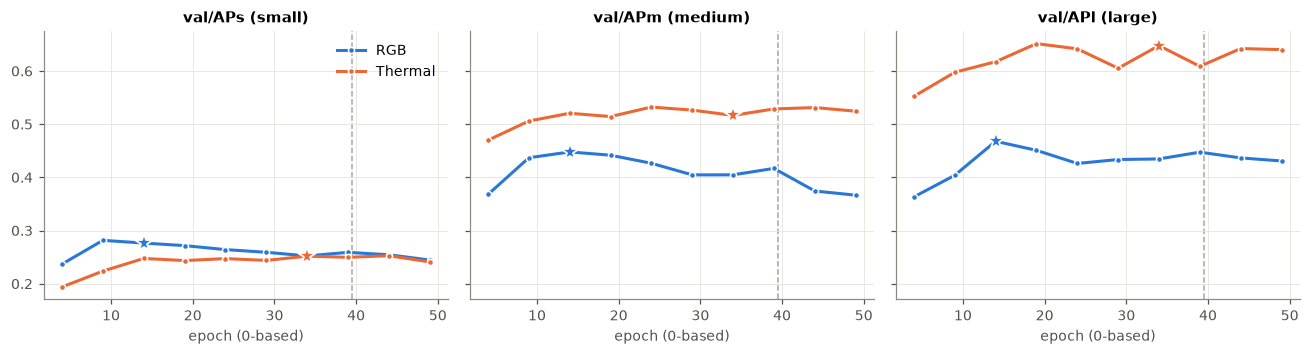

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharex=True, sharey=True)
for ax, (key, name) in zip(axes, [("APs", "small"), ("APm", "medium"), ("APl", "large")]):
    for k in FULL:
        ax.plot(val_epochs(k), val_metric(k, key), color=color(k), lw=2, marker="o", ms=4, mec="white", mew=1,
                label=MOD_LABEL[RUN_MOD[k]])
        mark_best(ax, k, key)
    mark_lr_drop(ax, text=False)
    ax.set_title(f"val/{key} ({name})")
    ax.set_xlabel("epoch (0-based)")
axes[0].legend(loc="upper right")
fig.tight_layout()

table(["run", "APs", "APm", "APl"],
      [[k, *(VAL[k][SUMMARY[k]["best_epoch"]]["metrics"][m] for m in ["APs", "APm", "APl"])] for k in FULL])

- **Small objects are the weak spot for both** (APS 0.25–0.28). At 448×560 one DINOv2 token covers 14×14 encoder pixels,
  about 16×13 pixels of the 640×512 frame, so many small FLIR boxes span one or two tokens.
- Thermal is ahead on medium and large objects and slightly behind on small ones. Again a diagnostic, not an H1 result.

### 3.4 Per-class AP50 vs class frequency

Is the spread in per-class AP just class imbalance? For each detector, three bars per class:
- **AP50** of its exported checkpoint (coloured);
- **share of train boxes** (light grey): the class's boxes over all boxes of the 6 kept classes in that modality's `train` split;
- **share of train images** (dark grey, hatched): the fraction of the frames the detector trained on (`n_train_frames`)
  that contain at least one box of the class. A class can be in many images with few boxes each, or the reverse.

Counts come from the F2 statistics (`projects/data_stats`, as-downloaded annotations). Classes are sorted by AP50,
separately for each detector. All bars are fractions, so they share one axis.

| class | RGB boxes | RGB box share | RGB images | RGB image share | RGB boxes / image | RGB % small | RGB AP50 | thermal boxes | thermal box share | thermal images | thermal image share | thermal boxes / image | thermal % small | thermal AP50 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| person | 35,007 | 21.4% | 6,870 | 68.4% | 5.1 | 78% | 0.641 | 50,478 | 29.8% | 8,205 | 78.4% | 6.2 | 80% | 0.731 |
| bike | 7,560 | 4.6% | 2,827 | 28.2% | 2.7 | 70% | 0.461 | 7,237 | 4.3% | 3,096 | 29.6% | 2.3 | 64% | 0.546 |
| car | 71,281 | 43.5% | 9,226 | 91.9% | 7.7 | 64% | 0.764 | 73,623 | 43.5% | 9,824 | 93.9% | 7.5 | 62% | 0.813 |
| motor | 1,837 | 1.1% | 948 | 9.4% | 1.9 | 64% | 0.598 | 1,116 | 0.7% | 744 | 7.1% | 1.5 | 41% | 0.630 |
| light | 18,640 | 11.4% | 3,805 | 37.9% | 4.9 | 97% | 0.479 | 16,198 | 9.6% | 3,695 | 35.3% | 4.4 | 97% | 0.557 |
| sign | 29,531 | 18.0% | 7,264 | 72.4% | 4.1 | 96% | 0.492 | 20,770 | 12.3% | 6,802 | 65.0% | 3.1 | 93% | 0.482 |

det_rgb: Spearman rank correlation AP50 vs box share = +0.66 (6 classes, descriptive only)
det_rgb: Spearman rank correlation AP50 vs image share = +0.54 (6 classes, descriptive only)
det_ir: Spearman rank correlation AP50 vs box share = +0.49 (6 classes, descriptive only)
det_ir: Spearman rank correlation AP50 vs image share = +0.49 (6 classes, descriptive only)


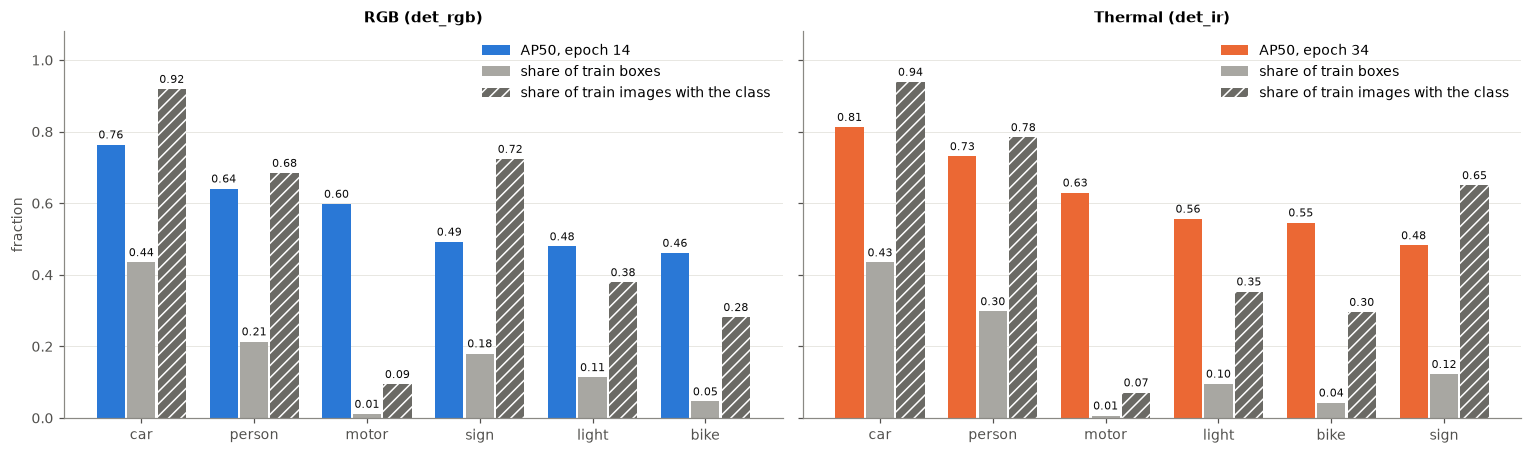

In [11]:
# F2 class statistics, pinned run (commit a4d65ef). Looked up in OUT first, then in $IRWM_OUTPUT_ROOT.
F2_RUN = "data_stats/2026-10-09/13-27-02/flir_stats.json"
f2_path = OUT / F2_RUN
if not f2_path.is_file():
    from irwm.utils.paths import load_env, output_root

    load_env()
    f2_path = output_root() / F2_RUN
F2 = read_json(f2_path)
f2_row = {(c["name"], c["modality"]): c for c in F2["classes"] if c["split"] == "train"}


def train_share(k):
    boxes = {c: f2_row[(c, RUN_MOD[k])]["boxes"] for c in CLASS_NAMES}
    return {c: n / sum(boxes.values()) for c, n in boxes.items()}


def image_share(k):
    """Fraction of the trained frames with at least one box of the class (dropped frames have no kept box)."""
    split = F2["images"][f"{RUN_MOD[k]}/train"]
    assert split["n_images"] - split["no_kept_box"] == SUMMARY[k]["n_train_frames"]
    return {c: f2_row[(c, RUN_MOD[k])]["images"] / SUMMARY[k]["n_train_frames"] for c in CLASS_NAMES}


IMG_GRAY = "#6b6a65"  # darker neutral + hatch: a second dataset statistic, not a second model
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
w = 0.27
for ax, k in zip(axes, FULL):
    ap50 = {c: VAL[k][SUMMARY[k]["best_epoch"]]["metrics"][f"AP50_{c}"] for c in CLASS_NAMES}
    share = train_share(k)
    order = sorted(CLASS_NAMES, key=ap50.get, reverse=True)
    x = np.arange(len(order))
    bars = [(-w, ap50, color(k), None, f"AP50, epoch {SUMMARY[k]['best_epoch']}"),
            (0, share, REF, None, "share of train boxes"),
            (w, image_share(k), IMG_GRAY, "///", "share of train images with the class")]
    for dx, vals, c, hatch, name in bars:
        ax.bar(x + dx, [vals[cl] for cl in order], width=w - 0.02, color=c, hatch=hatch, edgecolor="white",
               linewidth=0, label=name)
        for xi, cl in zip(x, order):
            ax.text(xi + dx, vals[cl] + 0.01, f"{vals[cl]:.2f}", ha="center", va="bottom", fontsize=7, color=INK)
    ax.set_xticks(x, order)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{MOD_LABEL[RUN_MOD[k]]} ({k})")
    ax.legend(loc="upper right")
axes[0].set_ylabel("fraction")
axes[0].set_ylim(0, 1.08)
fig.tight_layout()


def ranks(v):
    return np.argsort(np.argsort(v))


rows = []
for c in CLASS_NAMES:
    r = [c]
    for k in FULL:
        f = f2_row[(c, RUN_MOD[k])]
        r += [f"{f['boxes']:,}", f"{train_share(k)[c]:.1%}", f"{f['images']:,}", f"{image_share(k)[c]:.1%}",
              f"{f['boxes'] / f['images']:.1f}", f"{f['size_normalised']['S'] / f['boxes']:.0%}",
              f"{VAL[k][SUMMARY[k]['best_epoch']]['metrics'][f'AP50_{c}']:.3f}"]
    rows.append(r)
cols = ["boxes", "box share", "images", "image share", "boxes / image", "% small", "AP50"]
table(["class", *(f"RGB {c}" for c in cols), *(f"thermal {c}" for c in cols)], rows)
for k in FULL:
    ap50 = np.array([VAL[k][SUMMARY[k]["best_epoch"]]["metrics"][f"AP50_{c}"] for c in CLASS_NAMES])
    for name, fn in [("box share", train_share), ("image share", image_share)]:
        share = np.array([fn(k)[c] for c in CLASS_NAMES])
        rho = np.corrcoef(ranks(ap50), ranks(share))[0, 1]
        print(f"{k}: Spearman rank correlation AP50 vs {name} = {rho:+.2f} (6 classes, descriptive only)")

- **Frequency explains the top of the ranking**: car (43 % of boxes, in 92–94 % of images) and person (21–30 % of
  boxes, 68–78 % of images) are the two best classes in both detectors. The rank correlation of AP50 with either share
  is positive (box share +0.66 RGB / +0.49 thermal; image share +0.54 / +0.49), but with 6 classes it is descriptive only.
- **Motor breaks the pattern.** It is about 1 % of the boxes and in only 7–9 % of the images, yet third in AP50 in both
  detectors. Its boxes are small less often (64 % RGB, 41 % thermal) than any other class. Its AP50 also rests on only
  77 (RGB) / 55 (thermal) val boxes, so it is the noisiest per-class number here (see its swings in §3.2).
- **Sign is the clearest size-limited class.** It appears in 65–72 % of training images, third after car and person,
  so the head sees it constantly, yet it ranks near the bottom: 93–96 % of its boxes are small. Light is the same
  (in 35–38 % of images, 97 % small).
- So exposure, whether counted in boxes or in images, explains only part of the ranking; **object size is the stronger
  limit** on the weak classes (§3.3: APS ≈ 0.25–0.28). Separating the two properly needs per-class AP by size bucket (F6).

## 4. Checkpoint selection and the cost of the schedule

What the 50-epoch schedule bought. x is the wall time since the run started (from W&B `_runtime` at each validation),
which on one GPU equals GPU-hours. y is the best val AP seen so far, i.e. the checkpoint that would be exported if the
run had stopped there.

| run | stop after epoch | GPU-h | best AP so far | share of final best |
|---|---|---|---|---|
| det_rgb | 4 | 1.3 | 0.2473 | 81.8% |
| det_rgb | 9 | 2.7 | 0.2909 | 96.3% |
| det_rgb | 14 | 4.0 | 0.3021 | 100.0% |
| det_rgb | 19 | 5.4 | 0.3021 | 100.0% |
| det_rgb | 24 | 6.7 | 0.3021 | 100.0% |
| det_rgb | 29 | 8.1 | 0.3021 | 100.0% |
| det_rgb | 34 | 9.4 | 0.3021 | 100.0% |
| det_rgb | 39 | 10.7 | 0.3021 | 100.0% |
| det_rgb | 44 | 12.1 | 0.3021 | 100.0% |
| det_rgb | 49 | 13.4 | 0.3021 | 100.0% |
| det_ir | 4 | 1.4 | 0.2757 | 83.6% |
| det_ir | 9 | 2.8 | 0.3090 | 93.7% |
| det_ir | 14 | 4.2 | 0.3260 | 98.9% |
| det_ir | 19 | 5.6 | 0.3263 | 99.0% |
| det_ir | 24 | 7.0 | 0.3263 | 99.0% |
| det_ir | 29 | 8.4 | 0.3263 | 99.0% |
| det_ir | 34 | 9.8 | 0.3297 | 100.0% |
| det_ir | 39 | 11.1 | 0.3297 | 100.0% |
| det_ir | 44 | 12.5 | 0.3297 | 100.0% |
| det_ir | 49 | 13.9 | 0.3297 | 100.0% |

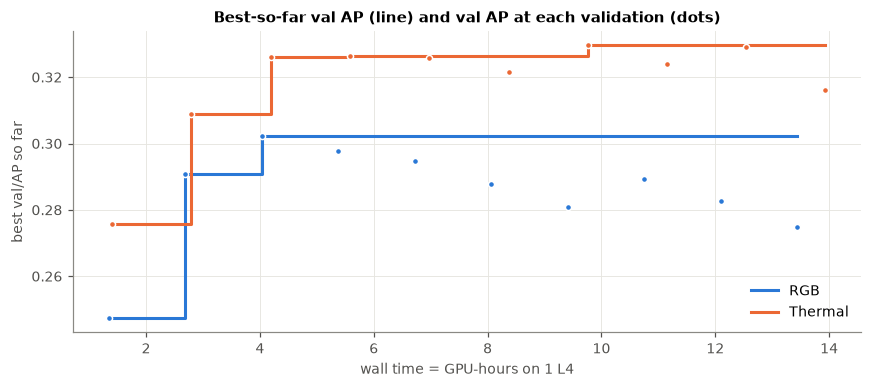

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
rows = []
for k in FULL:
    t, ap = series(k, "val/AP", x="_runtime")
    best_so_far = np.maximum.accumulate(ap)
    assert np.allclose(ap, val_metric(k, "AP"), atol=1e-6)
    ax.step(t / 3600, best_so_far, where="post", color=color(k), lw=2, label=MOD_LABEL[RUN_MOD[k]])
    ax.plot(t / 3600, ap, "o", ms=4, color=color(k), mec="white", mew=1)
    for e, ti, b in zip(val_epochs(k), t / 3600, best_so_far):
        rows.append([k, e, f"{ti:.1f}", f"{b:.4f}", f"{b / best_so_far[-1]:.1%}"])
ax.set_xlabel("wall time = GPU-hours on 1 L4")
ax.set_ylabel("best val/AP so far")
ax.set_title("Best-so-far val AP (line) and val AP at each validation (dots)")
ax.legend(loc="lower right")
fig.tight_layout()
table(["run", "stop after epoch", "GPU-h", "best AP so far", "share of final best"], rows)

- **RGB had its exported checkpoint after ≈ 4 GPU-hours** (epoch 14); the remaining ≈ 9.5 h did not improve it.
- **Thermal reached 99 % of its final best after ≈ 4.3 h** (epoch 14) and its best after ≈ 9.8 h (epoch 34, +0.004 AP).
- Caveat: these are truncations of *this* run, whose lr drop sits at epoch 40. A real 15–20-epoch schedule would drop the
  lr earlier and could end slightly higher. This is an observation for later runs (e.g. retraining heads in Phase 4),
  not a change to F8's spec.

## 5. Optimiser and mixed-precision health

`train/lr` from every 50-step sample, and the GradScaler scale at each epoch end (`16-mixed`). A scale that keeps
collapsing would mean overflowing fp16 gradients; a non-finite loss is counted in `train/nonfinite_steps`.

| run | lr, epochs 0–39 | lr, epochs 40–49 | grad scale range | max nonfinite_steps |
|---|---|---|---|---|
| det_rgb | ['1e-04'] | ['1e-05'] | 512–2048 | 0 |
| det_ir | ['1e-04'] | ['1e-05'] | 512–4096 | 0 |

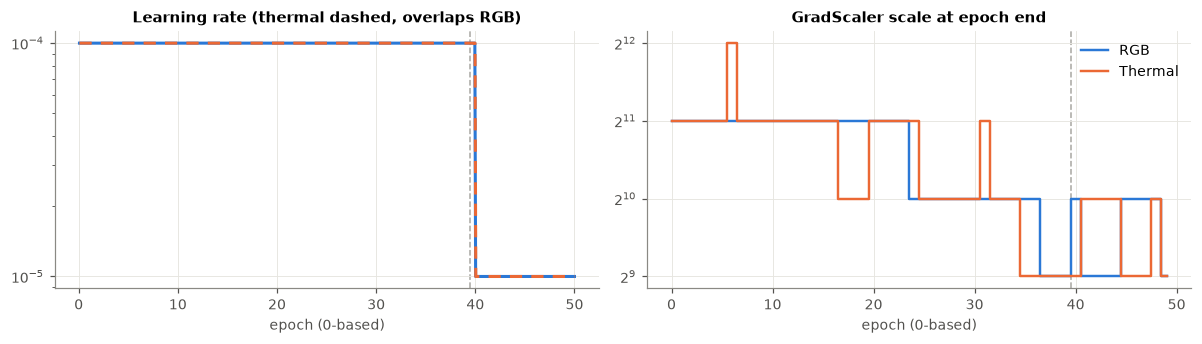

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for k in FULL:
    step, lr = series(k, "train/lr")
    axes[0].plot(step / steps_per_epoch(k), lr, color=color(k), lw=2, label=MOD_LABEL[RUN_MOD[k]],
                 ls="-" if k == "det_rgb" else (0, (4, 3)))
    gs = per_epoch(k, "train/grad_scale")
    axes[1].step(np.arange(50), gs, where="mid", color=color(k), lw=1.6, label=MOD_LABEL[RUN_MOD[k]])
axes[0].set_yscale("log")
axes[0].set_title("Learning rate (thermal dashed, overlaps RGB)")
axes[1].set_yscale("log", base=2)
axes[1].set_title("GradScaler scale at epoch end")
for ax in axes:
    mark_lr_drop(ax, text=False)
    ax.set_xlabel("epoch (0-based)")
axes[1].legend(loc="upper right")
fig.tight_layout()

rows = []
for k in FULL:
    step, lr = series(k, "train/lr")
    ep = step // steps_per_epoch(k)
    gs = per_epoch(k, "train/grad_scale")
    rows.append([k, sorted({f"{v:.0e}" for v in lr[ep < LR_DROP_EPOCH]}), sorted({f"{v:.0e}" for v in lr[ep >= LR_DROP_EPOCH]}),
                 f"{int(gs.min())}–{int(gs.max())}", int(series(k, "train/nonfinite_steps")[1].max())])
table(["run", "lr, epochs 0–39", "lr, epochs 40–49", "grad scale range", "max nonfinite_steps"], rows)

- **The lr schedule is exactly as specified**: 1e-4 for epochs 0–39 and 1e-5 for 40–49, in both runs.
- **fp16 was healthy**: zero non-finite steps in both runs, and the GradScaler scale moved only between 512 and 4096
  (a few halvings, then growth back), never collapsing.

## 6. Compute cost

Per-epoch timing logged by `DetectorModule` (medians over the steps timed in that epoch), and the GPU's own telemetry
from W&B system metrics (sampled every ≈ 15 s; utilisation and power are smoothed with a 5-min rolling median). GPU memory is what NVML reports as in use, so it includes the PyTorch
caching allocator's reserve.

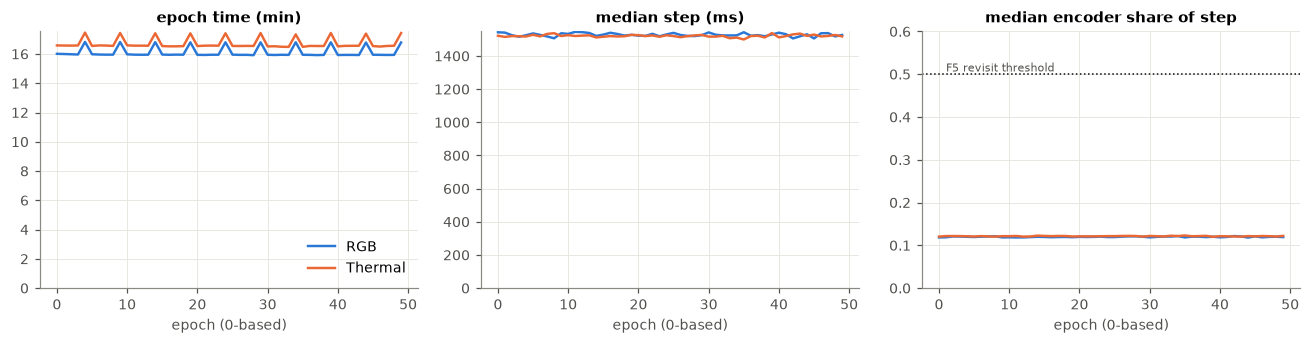

In [14]:
PERF = [("perf/epoch_s", "epoch time (min)", 1 / 60), ("perf/step_ms", "median step (ms)", 1),
        ("perf/encode_share", "median encoder share of step", 1)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
for ax, (key, name, scale) in zip(axes, PERF):
    for k in FULL:
        ax.plot(np.arange(50), per_epoch(k, key) * scale, color=color(k), lw=1.6, label=MOD_LABEL[RUN_MOD[k]])
    ax.set_title(name)
    ax.set_xlabel("epoch (0-based)")
    ax.set_ylim(0, None)
axes[2].axhline(0.5, color=INK, lw=1, ls=":")
axes[2].text(1, 0.5, "F5 revisit threshold", fontsize=7.5, color=MUTED, va="bottom")
axes[2].set_ylim(0, 0.6)
axes[0].legend(loc="lower right")
fig.tight_layout()

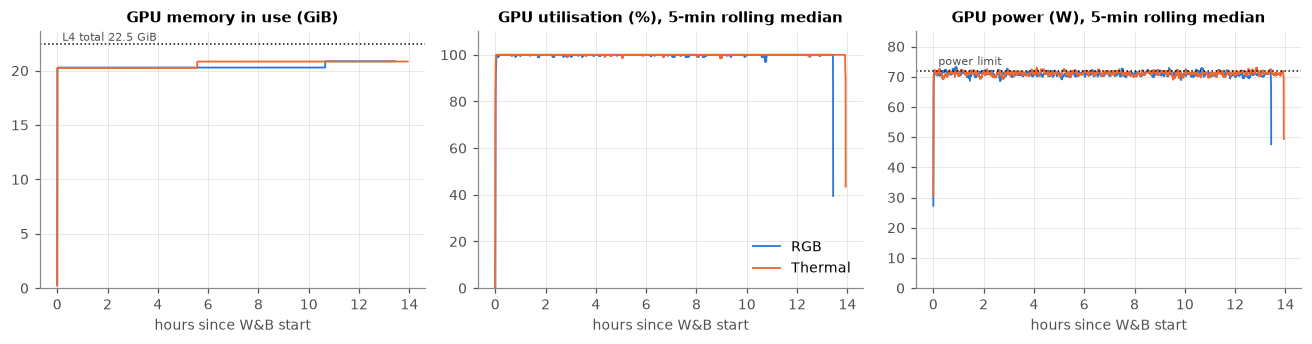

In [15]:
def rolling_median(y, n=20):
    """Centred rolling median over n samples (≈ 5 min at W&B's 15 s sampling)."""
    win = np.lib.stride_tricks.sliding_window_view(np.pad(y, n // 2, mode="edge"), n)
    return np.median(win, axis=1)[:len(y)]


GPU = [("gpu.0.memoryAllocatedBytes", "GPU memory in use (GiB)", 1 / 2**30), ("gpu.0.gpu", "GPU utilisation (%)", 1),
       ("gpu.0.powerWatts", "GPU power (W)", 1)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
gpu_rows = {}
for k in FULL:
    stats = [s for s in WB[k][2] if "gpu.0.gpu" in s]
    t = (np.array([s["_timestamp"] for s in stats]) - stats[0]["_timestamp"]) / 3600
    gpu_rows[k] = {key: np.array([s[key] for s in stats], float) for key, *_ in GPU}
    gpu_rows[k]["limit_w"] = stats[0]["gpu.0.enforcedPowerLimitWatts"]
    for ax, (key, name, scale) in zip(axes, GPU):
        y = gpu_rows[k][key] * scale
        ax.plot(t, y if key == "gpu.0.memoryAllocatedBytes" else rolling_median(y), color=color(k), lw=1.2,
                label=MOD_LABEL[RUN_MOD[k]])
total_gib = int(WB_META["det_rgb"]["gpu_nvidia"][0]["memoryTotal"]) / 2**30
axes[0].axhline(total_gib, color=INK, lw=1, ls=":")
axes[0].text(0.2, total_gib, f"L4 total {total_gib:.1f} GiB", fontsize=7.5, color=MUTED, va="bottom")
axes[2].axhline(gpu_rows["det_rgb"]["limit_w"], color=INK, lw=1, ls=":")
axes[2].text(0.2, gpu_rows["det_rgb"]["limit_w"] + 1, "power limit", fontsize=7.5, color=MUTED, va="bottom")
axes[1].set_ylim(0, 110)
axes[2].set_ylim(0, 85)
for ax, (_, name, _) in zip(axes, GPU):
    ax.set_title(name if ax is axes[0] else f"{name}, 5-min rolling median")
    ax.set_xlabel("hours since W&B start")
    ax.set_ylim(0, ax.get_ylim()[1])
axes[1].legend(loc="lower right")
fig.tight_layout()

In [16]:
rows = []
for k in FULL:
    g = gpu_rows[k]
    rows.append([k, f"{np.median(per_epoch(k, 'perf/step_ms')):.0f}", f"{np.median(per_epoch(k, 'perf/encode_ms')):.0f}",
                 f"{np.median(per_epoch(k, 'perf/encode_share')):.3f}", f"{np.median(per_epoch(k, 'perf/train_images_per_s')):.2f}",
                 f"{np.median(per_epoch(k, 'perf/epoch_s')) / 60:.1f}", f"{g['gpu.0.memoryAllocatedBytes'].max() / 2**30:.2f}",
                 f"{np.median(g['gpu.0.gpu']):.0f}", f"{np.median(g['gpu.0.powerWatts']):.0f} / {g['limit_w']:.0f}",
                 f"{SUMMARY[k]['fit_wall_s'] / 3600:.1f}"])
table(["run", "step (ms)", "encode (ms)", "encode share", "img/s", "epoch (min)", "peak GPU mem (GiB)",
       "GPU util (%)", "power / limit (W)", "GPU-h (fit)"], rows)

| run | step (ms) | encode (ms) | encode share | img/s | epoch (min) | peak GPU mem (GiB) | GPU util (%) | power / limit (W) | GPU-h (fit) |
|---|---|---|---|---|---|---|---|---|---|
| det_rgb | 1527 | 183 | 0.120 | 10.48 | 15.9 | 20.87 | 100 | 71 / 72 | 13.4 |
| det_ir | 1520 | 185 | 0.122 | 10.52 | 16.6 | 20.84 | 100 | 71 / 72 | 13.9 |

- **Encoding is not the bottleneck**: the frozen SDPA encoder takes ≈ 184 ms of a ≈ 1.52 s step (12 %), flat over all
  50 epochs, far below the 0.5 threshold that would reopen F5. The DINO-DETR head is the other 88 %.
- **The L4 is saturated**: median utilisation is 100 % and power sits at the 72 W limit, so a faster GPU, not more
  loader workers, is what would shorten a run. The validation passes (every ≈ 1.35 h) dip for less than the
  5-min window, so the median hides them; the drop at the end is teardown.
- Step time is flat over the 50 epochs. The epoch-time spikes every 5th epoch (≈ +0.8 min) are the validation pass,
  which runs before `on_train_epoch_end` and so is counted in `perf/epoch_s`.
- Memory in use is ≈ 20.9 GiB of 22.5 GiB at batch 16, after two small steps up of the caching allocator's reserve. The allocator's own peak (overfits, §7) is ≈ 18.1–18.2 GiB,
  so batch 16 at 448×560 is close to the L4 limit.

## 7. Overfit gate (plan Step 9)

Before the full runs, each pipeline had to reach AP50 ≥ 0.8 for person and car on 256 train frames (validated on the
same frames), with constant lr. This proves the data → encoder → head → COCO-eval path end to end.

In [17]:
rows = []
for k in OVERFIT:
    d = OVERFIT_JSON[k]
    for v in d["validations"]:
        m = v["metrics"]
        rows.append([k, WB_META[k]["gpu"], v["global_step"], f"{m['AP50_person']:.3f}", f"{m['AP50_car']:.3f}", f"{m['AP']:.3f}",
                     "✅" if min(m["AP50_person"], m["AP50_car"]) >= d["ap50_bar"] else "–"])
    assert d["passed"]
table(["run", "GPU", "step", "AP50 person", "AP50 car", "AP", "≥ 0.8 on both"], rows)
table(["run", "passed at step", "median step (ms)", "allocator peak (GiB)", "fit wall (min)"],
      [[k, OVERFIT_JSON[k]["passed_step"], f"{OVERFIT_JSON[k]['median_step_ms']:.0f}",
        f"{OVERFIT_JSON[k]['peak_mem_gib']:.2f}", f"{OVERFIT_JSON[k]['fit_wall_s'] / 60:.1f}"] for k in OVERFIT])

| run | GPU | step | AP50 person | AP50 car | AP | ≥ 0.8 on both |
|---|---|---|---|---|---|---|
| overfit_rgb | NVIDIA L4 | 500 | 0.895 | 0.901 | 0.423 | ✅ |
| overfit_ir | Tesla V100S-PCIE-32GB | 500 | 0.769 | 0.791 | 0.316 | – |
| overfit_ir | Tesla V100S-PCIE-32GB | 1000 | 0.939 | 0.969 | 0.672 | ✅ |

| run | passed at step | median step (ms) | allocator peak (GiB) | fit wall (min) |
|---|---|---|---|---|
| overfit_rgb | 500 | 1520 | 18.13 | 13.2 |
| overfit_ir | 1000 | 851 | 18.23 | 15.1 |

- Both passed: RGB at step 500, thermal at step 1000 (thermal was 0.77 / 0.79 at step 500, just under the bar).
- The thermal overfit's 851 ms step is a V100S, not an L4, so it is not a speed comparison.

## 8. Frozen exports

The exported heads (`$IRWM_CKPT_ROOT/detection/frozen/<name>/`) must come from the best-`val/AP` checkpoint, carry the
same val metrics as the run, and match their recorded SHA-256. This is what `load_frozen_detector` checks at load time.

In [18]:
rows = []
for k in FULL:
    meta = FROZEN[k]
    sha = hashlib.sha256((CKPT / "detection/frozen" / k / "head.pt").read_bytes()).hexdigest()
    run_val = VAL[k][SUMMARY[k]["best_epoch"]]["metrics"]
    max_diff = max(abs(meta["val_metrics"]["metrics"][m] - run_val[m]) for m in run_val)
    ok = sha == meta["head_sha256"] and meta["epoch"] == SUMMARY[k]["best_epoch"] and max_diff < 1e-8
    rows.append([k, f"`{meta['source_ckpt']}`", meta["epoch"], f"{max_diff:.1e}", f"`{sha[:12]}…`",
                 sha == meta["head_sha256"], f"`{meta['git']['commit'][:7]}`", meta["encoder"]["attention"],
                 meta["encoder"]["encoder_tag"], "✅" if ok else "❌"])
    assert ok
table(["name", "source checkpoint", "epoch", "max |Δ| val metrics", "head.pt sha256", "sha matches",
       "commit", "attention", "encoder tag", "ok"], rows)

| name | source checkpoint | epoch | max |Δ| val metrics | head.pt sha256 | sha matches | commit | attention | encoder tag | ok |
|---|---|---|---|---|---|---|---|---|---|
| det_rgb | `detection/slurm-5526115/best-e014.ckpt` | 14 | 0.0e+00 | `96db506529ba…` | True | `b81ef6c` | sdpa | dinov2_vitb14reg_448x560_l3-6-9-12_pca1152 | ✅ |
| det_ir | `detection/slurm-5526116/best-e034.ckpt` | 34 | 0.0e+00 | `2ff38732df45…` | True | `b81ef6c` | sdpa | dinov2_vitb14reg_448x560_l3-6-9-12_pca1152 | ✅ |

- Both exports are the best-`val/AP` checkpoints, their val metrics match the run's JSON exactly, and the head files
  hash to the recorded SHA-256.
- Downstream code (F9, F12) must encode with the same settings as the export: `encoder.attention: sdpa`, fp16,
  `dinov2_vitb14reg_448x560_l3-6-9-12_pca1152`.

## 9. Takeaways and caveats for F6 / F9

**What F8 delivers.** Two frozen DINO-DETR heads on frozen DINOv2-Reg PCA features that clearly detect people and cars in
both modalities, trained without numerical trouble and selected on val.

**What this notebook does *not* show:**
- **No H1 answer.** The RGB/thermal gap (0.302 vs 0.330 AP) is on *different val sets*. H1 is the F9 comparison on the
  video-test split with the F6 evaluator and bootstrap CIs.
- **Optimistic numbers.** Val chose the checkpoint and also scores it.
- **One seed per detector**, so no estimate of run-to-run variance; the thermal plateau (±0.005 AP) is likely within it.
- **RGB is overfit-limited.** If the heads are retrained (e.g. in Phase 4), a shorter schedule or stronger augmentation
  for RGB is worth testing. Any such change must be applied to both modalities to keep the comparison fair.
- **Small objects are weak in both** (APS ≈ 0.25–0.28). Small-box errors will be the first place where degraded
  predicted features (H2/H3) could show, so F12 should report APS separately.